<!-- project-navigation -->
# 19_predict_with_explain
Role: Prediction and SHAP on prepared features.

See [notebook guide](README.md) and [model comparison](../reports/model_comparison.md). Historical code and outputs are retained; run with the project root as working directory.


In [1]:
# ============================================================
# 19_Prediction_Explainability.ipynb
# PRÉDICTION + EXPLICABILITÉ SHAP
# ============================================================

import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

# Modèle
model = joblib.load(
    "data/models/lightgbm_scale_pos_weight.pkl"
)

# Features attendues
feature_names = joblib.load(
    "data/models/lightgbm_feature_names.pkl"
)

# Métadonnées
metadata = joblib.load(
    "data/models/lightgbm_metadata.pkl"
)

# SHAP
explainer = shap.TreeExplainer(model)

print("✓ Modèle chargé")
print("✓ Features chargées :", len(feature_names))
print("✓ Métadonnées chargées")

c:\Users\Asus\OneDrive\Bureau\FinTech\.venv-1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Modèle chargé
✓ Features chargées : 240
✓ Métadonnées chargées


In [2]:
# ============================================================
# PARAMÈTRES DE DÉCISION
# ============================================================

FINAL_THRESHOLD = metadata["final_threshold"]

print("Seuil final :", FINAL_THRESHOLD)

Seuil final : 0.68


In [3]:
# ============================================================
# FONCTION DE PRÉDICTION
# ============================================================

def predict_client(X_client):
    
    X_client = X_client.copy()
    
    # Vérification des colonnes
    missing_features = [
        col for col in feature_names
        if col not in X_client.columns
    ]
    
    extra_features = [
        col for col in X_client.columns
        if col not in feature_names
    ]
    
    if missing_features:
        raise ValueError(
            f"Features manquantes : {missing_features}"
        )
    
    # Garder exactement les 240 features
    X_client = X_client[feature_names]
    
    # Vérification NaN
    if X_client.isnull().sum().sum() > 0:
        raise ValueError(
            "Le client contient des valeurs manquantes."
        )
    
    # Vérification inf
    if np.isinf(X_client.select_dtypes(include=np.number)).sum().sum() > 0:
        raise ValueError(
            "Le client contient des valeurs infinies."
        )
    
    # Probabilité
    probability = model.predict_proba(X_client)[0, 1]
    
    # Décision
    prediction = int(probability >= FINAL_THRESHOLD)
    
    if prediction == 1:
        decision = "Risque élevé"
    else:
        decision = "Risque faible"
    
    return {
        "probability_default": probability,
        "prediction": prediction,
        "decision": decision
    }

In [4]:
# ============================================================
# FONCTION DE PRÉDICTION
# ============================================================

def predict_client(X_client):
    
    X_client = X_client.copy()
    
    # Vérification des colonnes
    missing_features = [
        col for col in feature_names
        if col not in X_client.columns
    ]
    
    extra_features = [
        col for col in X_client.columns
        if col not in feature_names
    ]
    
    if missing_features:
        raise ValueError(
            f"Features manquantes : {missing_features}"
        )
    
    # Garder exactement les 240 features
    X_client = X_client[feature_names]
    
    # Vérification NaN
    if X_client.isnull().sum().sum() > 0:
        raise ValueError(
            "Le client contient des valeurs manquantes."
        )
    
    # Vérification inf
    if np.isinf(X_client.select_dtypes(include=np.number)).sum().sum() > 0:
        raise ValueError(
            "Le client contient des valeurs infinies."
        )
    
    # Probabilité
    probability = model.predict_proba(X_client)[0, 1]
    
    # Décision
    prediction = int(probability >= FINAL_THRESHOLD)
    
    if prediction == 1:
        decision = "Risque élevé"
    else:
        decision = "Risque faible"
    
    return {
        "probability_default": probability,
        "prediction": prediction,
        "decision": decision
    }

In [6]:
# ============================================================
# CHARGEMENT DES DONNÉES DE VALIDATION POUR LE TEST
# ============================================================

X_train, X_valid, y_train, y_valid = joblib.load(
    "data/processed/xgb_split.pkl"
)

print("X_valid :", X_valid.shape)

X_valid : (61503, 240)


In [7]:
# ============================================================
# TEST SUR UN CLIENT
# ============================================================

client_test = X_valid.iloc[[2]].copy()

result = predict_client(client_test)

print("======================================")
print("RÉSULTAT DE LA PRÉDICTION")
print("======================================")

print(
    f"Probabilité de défaut : "
    f"{result['probability_default']:.4f}"
)

print(
    f"Seuil de décision     : "
    f"{FINAL_THRESHOLD:.2f}"
)

print(
    f"Décision              : "
    f"{result['decision']}"
)

RÉSULTAT DE LA PRÉDICTION
Probabilité de défaut : 0.7883
Seuil de décision     : 0.68
Décision              : Risque élevé


In [8]:
# ============================================================
# FONCTION D'EXPLICATION SHAP
# ============================================================

def explain_client(X_client, max_display=15):
    
    X_client = X_client.copy()
    
    # Même ordre de features
    X_client = X_client[feature_names]
    
    # SHAP
    shap_values = explainer.shap_values(X_client)
    
    # Gestion des différentes versions SHAP
    if isinstance(shap_values, list):
        shap_values_default = shap_values[1]
    else:
        shap_values_default = shap_values
    
    # Valeur de base
    if isinstance(explainer.expected_value, list):
        base_value = explainer.expected_value[1]
    else:
        base_value = explainer.expected_value
    
    explanation = shap.Explanation(
        values=shap_values_default[0],
        base_values=base_value,
        data=X_client.iloc[0].values,
        feature_names=feature_names
    )
    
    shap.waterfall_plot(
        explanation,
        max_display=max_display
    )
    
    return explanation

In [9]:
# ============================================================
# FONCTION D'EXPLICATION SHAP
# ============================================================

def explain_client(X_client, max_display=15):
    
    X_client = X_client.copy()
    
    # Même ordre de features
    X_client = X_client[feature_names]
    
    # SHAP
    shap_values = explainer.shap_values(X_client)
    
    # Gestion des différentes versions SHAP
    if isinstance(shap_values, list):
        shap_values_default = shap_values[1]
    else:
        shap_values_default = shap_values
    
    # Valeur de base
    if isinstance(explainer.expected_value, list):
        base_value = explainer.expected_value[1]
    else:
        base_value = explainer.expected_value
    
    explanation = shap.Explanation(
        values=shap_values_default[0],
        base_values=base_value,
        data=X_client.iloc[0].values,
        feature_names=feature_names
    )
    
    shap.waterfall_plot(
        explanation,
        max_display=max_display
    )
    
    return explanation

In [11]:
print("predict_client :", "OK" if "predict_client" in globals() else "MANQUANTE")
print("explain_client :", "OK" if "explain_client" in globals() else "MANQUANTE")
print("predict_with_explain :", "OK" if "predict_with_explain" in globals() else "MANQUANTE")

predict_client : OK
explain_client : OK
predict_with_explain : MANQUANTE


In [12]:
# ============================================================
# FONCTION COMPLETE : PREDICTION + EXPLICATION SHAP
# ============================================================

def predict_with_explain(X_client, max_display=15):

    # -------------------------
    # PREDICTION
    # -------------------------

    result = predict_client(X_client)

    # -------------------------
    # SHAP
    # -------------------------

    explanation = explain_client(
        X_client,
        max_display=max_display
    )

    # -------------------------
    # TOP VARIABLES
    # -------------------------

    shap_df = pd.DataFrame({
        "Feature": feature_names,
        "Value": X_client[feature_names].iloc[0].values,
        "SHAP_Value": explanation.values
    })

    shap_df["Abs_SHAP"] = np.abs(
        shap_df["SHAP_Value"]
    )

    shap_df = (
        shap_df
        .sort_values(
            "Abs_SHAP",
            ascending=False
        )
        .reset_index(drop=True)
    )

    result["top_features"] = shap_df.head(10)

    return result

print("✓ Fonction predict_with_explain() créée")

✓ Fonction predict_with_explain() créée


c:\Users\Asus\OneDrive\Bureau\FinTech\.venv-1\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


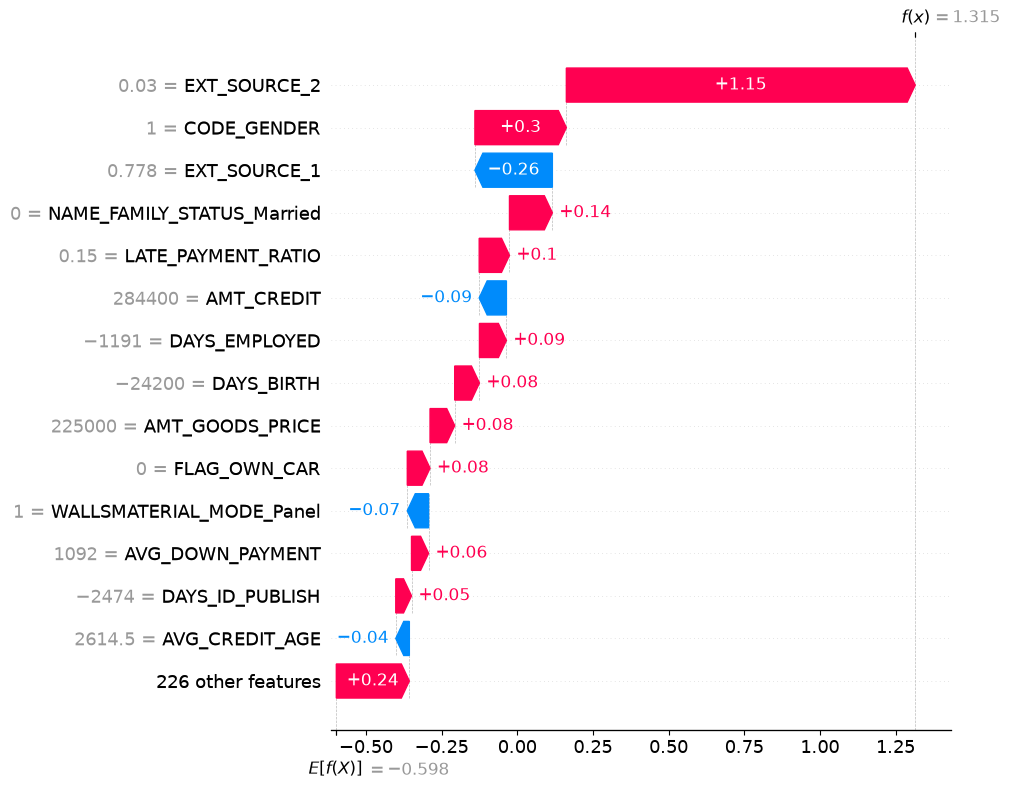

PRÉDICTION DU CLIENT
Probabilité de défaut : 0.7883
Seuil                 : 0.68
Décision              : Risque élevé

Top variables explicatives :
                      Feature          Value  SHAP_Value
0                EXT_SOURCE_2       0.030108    1.152708
1                 CODE_GENDER       1.000000    0.302137
2                EXT_SOURCE_1       0.778177   -0.255915
3  NAME_FAMILY_STATUS_Married       0.000000    0.141693
4          LATE_PAYMENT_RATIO       0.150000    0.100041
5                  AMT_CREDIT  284400.000000   -0.089891
6               DAYS_EMPLOYED   -1191.000000    0.089079
7                  DAYS_BIRTH  -24200.000000    0.081752
8             AMT_GOODS_PRICE  225000.000000    0.081479
9                FLAG_OWN_CAR       0.000000    0.075141


In [13]:
# ============================================================
# TEST FINAL
# ============================================================

client_test = X_valid.iloc[[2]].copy()

result = predict_with_explain(
    client_test,
    max_display=15
)

print("============================================")
print("PRÉDICTION DU CLIENT")
print("============================================")

print(
    f"Probabilité de défaut : "
    f"{result['probability_default']:.4f}"
)

print(
    f"Seuil                 : "
    f"{FINAL_THRESHOLD:.2f}"
)

print(
    f"Décision              : "
    f"{result['decision']}"
)

print("\nTop variables explicatives :")

print(
    result["top_features"][
        ["Feature", "Value", "SHAP_Value"]
    ].head(10)
)